<a href="https://colab.research.google.com/github/Nina-Cyndy/diabetes-intro-to-ml-summative/blob/main/diabetes_readmission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting 30-Day Hospital Readmission in Diabetic Patients
**Summative Project: Machine Learning (traditional ML vs. deep learning)**

**Task:** multi-class classification of `readmitted` (`<30`, `>30`, `NO`) using the *Diabetes 130-US Hospitals (1999-2008)* dataset from the UCI Machine Learning Repository.

**Notebook map**

| Section | Content | Status |
|---|---|---|
| 1 | Setup, seeds and configuration | Day 1 |
| 2 | Data loading | Day 1 |
| 3 | Exploratory data analysis | Day 1 |
| 4 | Data cleaning and patient-level split | Day 1 |
| 5 | Feature engineering | Day 2 |
| 6 | Traditional ML (scikit-learn) | Day 2 |
| 7 | Deep learning (TensorFlow/Keras + `tf.data`) | Day 3 |
| 8 | Evaluation and error analysis | Day 4 |
| 9 | Experiment table and conclusions | Day 4 |

**Running on Google Colab:** upload `diabetic_data.csv` and `IDs_mapping.csv` into a `data/` folder (or mount Drive and change `DATA_DIR` in section 1), then run all cells from the top.

## 1. Setup, seeds and configuration
All randomness is controlled by a single `SEED`, and all paths are defined once in this cell so the notebook is reproducible from top to bottom. Weights & Biases is forced into **offline mode** so runs are logged locally without an account (the rubric asks for W&B offline or TensorBoard logs backing the experiment table).

In [1]:
# Uncomment on Colab / a fresh environment
!pip install -q -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 101.1 MB/s eta 0:00:00


In [3]:
import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

# ---- Reproducibility ----
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
try:
    import tensorflow as tf
    tf.random.set_seed(SEED)
    print("TensorFlow", tf.__version__)
except ImportError:
    print("TensorFlow not installed here (needed from Section 7 onwards).")

PROJECT_DIR = Path("/content/drive/MyDrive/diabetes_project")

DATA_DIR = PROJECT_DIR / "data"                 # diabetic_data.csv + IDs_mapping.csv go here
PROCESSED_DIR = DATA_DIR / "processed"          # cleaned train/val/test splits
FIG_DIR = PROJECT_DIR / "figures"               # all saved plots
MODEL_DIR = PROJECT_DIR / "saved_models"        # .joblib and .h5 / SavedModel files
LOG_DIR = PROJECT_DIR / "logs"                  # TensorBoard logs

# ---- Weights & Biases offline mode ----
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_DIR"] = str(PROJECT_DIR)

for d in (DATA_DIR, PROCESSED_DIR, FIG_DIR, MODEL_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "diabetic_data.csv"
TARGET = "readmitted"
CLASS_ORDER = ["NO", ">30", "<30"]

ID_CODE_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
# discharge_disposition_id values meaning the patient died or went to hospice (see IDs_mapping.csv)
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]

sns.set_theme(style="whitegrid", context="notebook")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0


## 2. Data loading
In this file, missing values are coded as the string `"?"`. I convert them to real `NaN` while loading. Default pandas NA-parsing is switched off on purpose: the strings `"None"` (in `A1Cresult` and `max_glu_serum`) and `"NO"` (in the target) are **valid categories**, not missing values. `"None"` means the test was not performed, which can itself be clinically informative.

In [4]:
def load_raw(path: Path) -> pd.DataFrame:
    """Load the raw CSV, treating only '?' as missing."""
    return pd.read_csv(path, na_values=["?"], keep_default_na=False, low_memory=False)

raw = load_raw(DATA_FILE)
assert len(raw) >= 20_000, "Brief requires at least 20,000 raw rows"
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns  (brief minimum: 20,000 rows)")
raw.head()

Raw shape: 101,766 rows x 50 columns  (brief minimum: 20,000 rows)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

## 3. Exploratory data analysis
Each analysis below is followed by a short interpretation cell. **Fill in the interpretation cells in your own words after you look at the output**; the written report draws directly on them.

### 3.1 Target distribution

,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


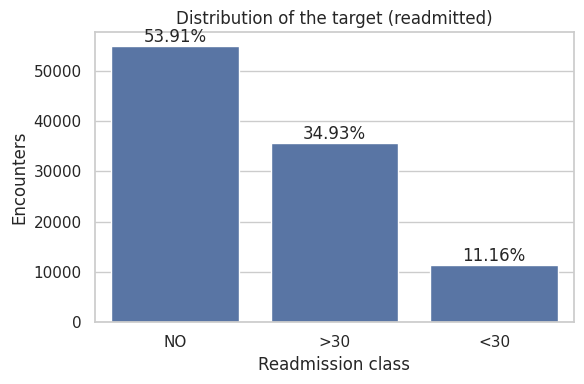

In [6]:
counts = raw[TARGET].value_counts().reindex(CLASS_ORDER)
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, order=CLASS_ORDER)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{pct.iloc[i]}%", ha="center", va="bottom")
ax.set(title="Distribution of the target (readmitted)", xlabel="Readmission class", ylabel="Encounters")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_distribution.png", dpi=200); plt.show()

**Interpretation (write your own):** How imbalanced is the target? Which class is the minority, and why does that matter for choosing metrics (macro-F1, per-class recall, ROC-AUC) instead of plain accuracy?

### 3.2 Missing values

In [7]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    m = df.isna().sum()
    out = pd.DataFrame({"missing": m, "percent": (m / len(df) * 100).round(2)})
    return out[out["missing"] > 0].sort_values("percent", ascending=False)

missing_report(raw)

,missing,percent
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


**Interpretation (write your own):** Which columns have the most missing data? Decide for each (drop, impute, or keep as an explicit "Unknown" category) and justify it. The defaults used in Section 4 are: drop `weight`, label missing `race`, `payer_code` and `medical_specialty` as "Unknown".

### 3.3 Numeric features: distributions and outliers

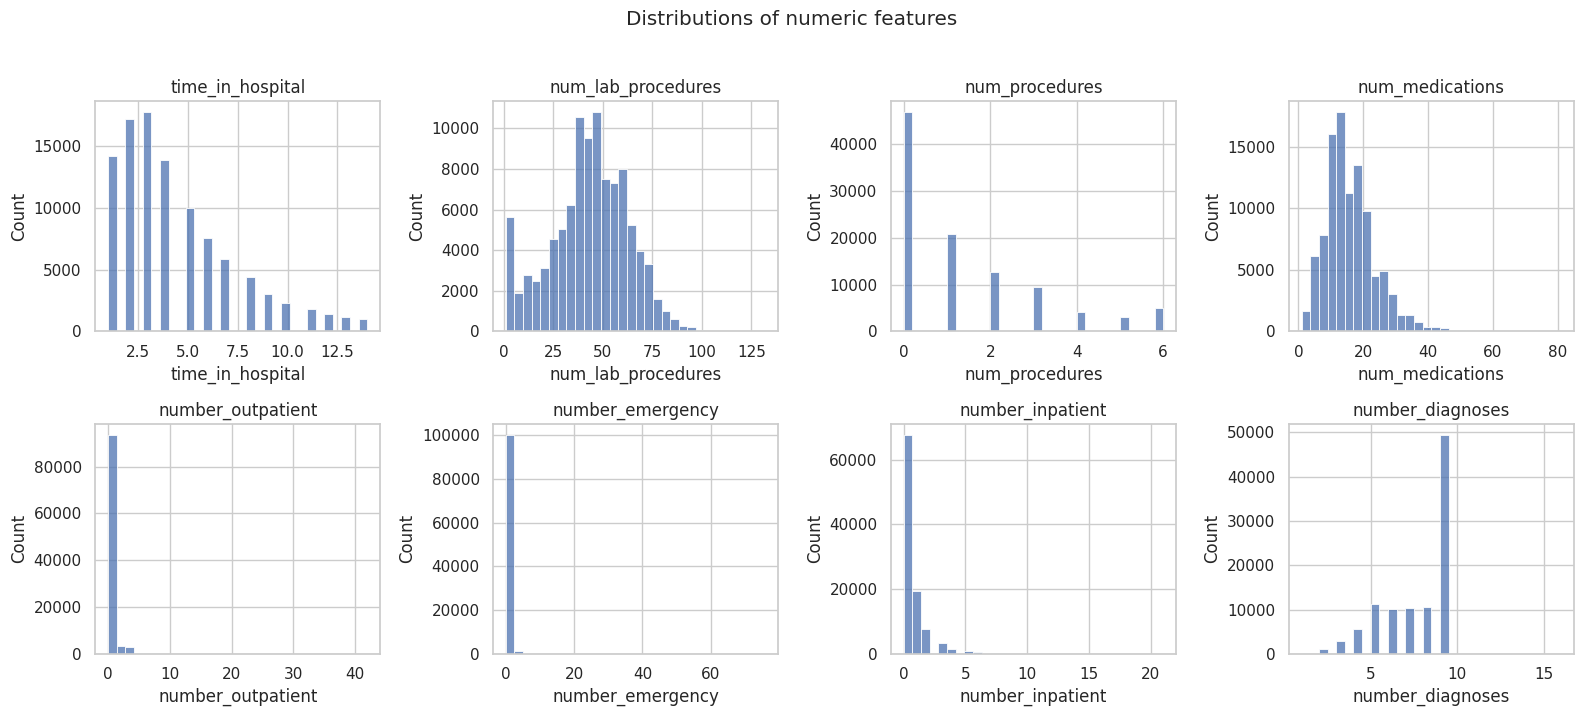

,min,median,max,outliers_IQR,outlier_pct
feature,,,,,
time_in_hospital,1,4.0,14,2252,2.21
num_lab_procedures,1,44.0,132,143,0.14
num_procedures,0,1.0,6,4954,4.87
num_medications,1,15.0,81,2557,2.51
number_outpatient,0,0.0,42,16739,16.45
number_emergency,0,0.0,76,11383,11.19
number_inpatient,0,0.0,21,7049,6.93
number_diagnoses,1,8.0,16,281,0.28


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(raw[col], bins=30, ax=ax)
    ax.set_title(col)
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

def iqr_outlier_table(df: pd.DataFrame, cols) -> pd.DataFrame:
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
        rows.append({"feature": c, "min": df[c].min(), "median": df[c].median(), "max": df[c].max(),
                     "outliers_IQR": n_out, "outlier_pct": round(n_out / len(df) * 100, 2)})
    return pd.DataFrame(rows).set_index("feature")

iqr_outlier_table(raw, NUM_COLS)

**Interpretation (write your own):** Which features are right-skewed or have long tails? Are the extreme values plausible clinically (e.g., many prior visits) or errors? Decide whether to clip, log-transform, or leave them, since tree models and neural networks react differently to skew.

### 3.4 Readmission rate against key features

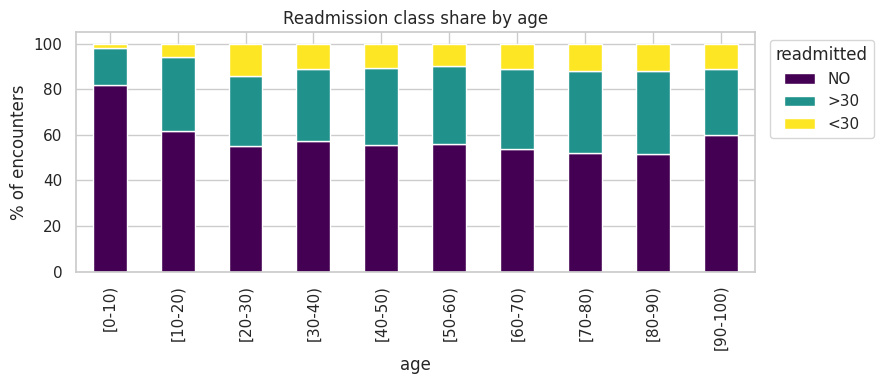

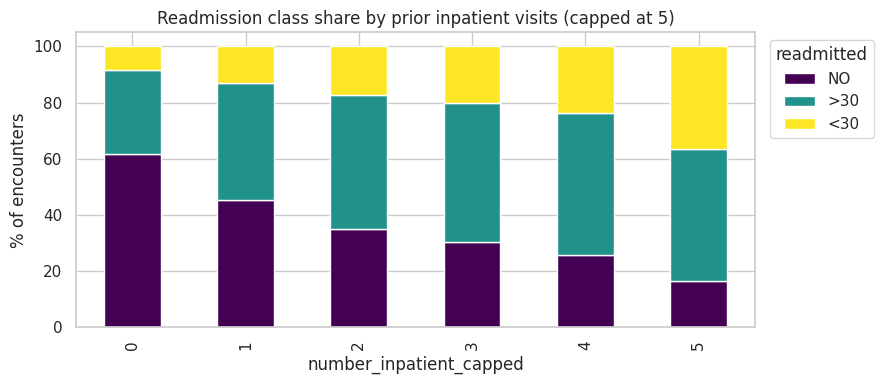

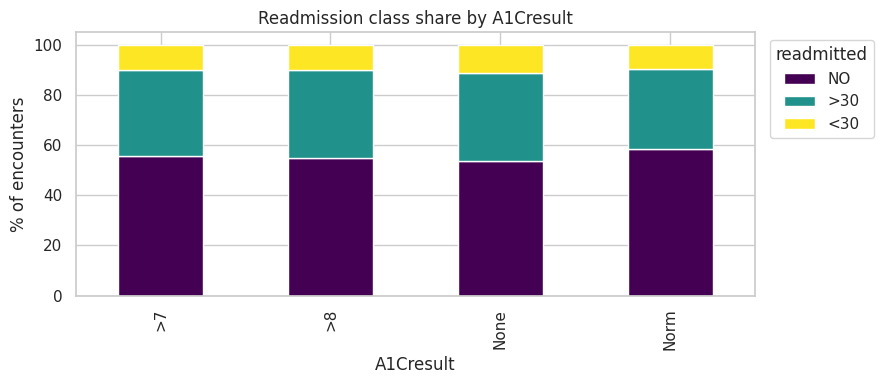

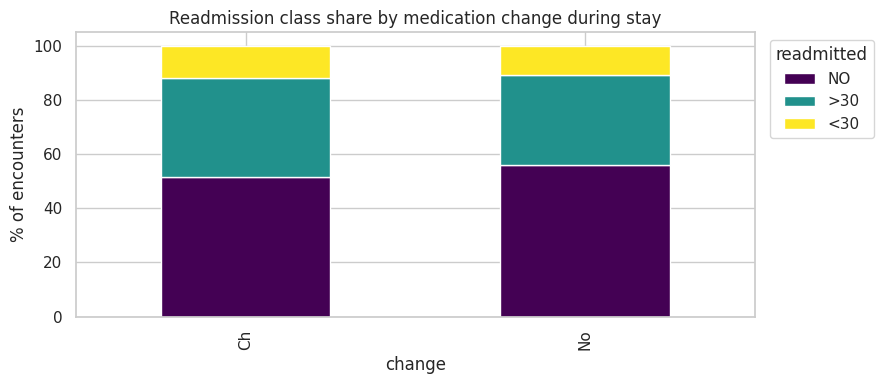

In [9]:
def class_share_plot(df: pd.DataFrame, col: str, order=None, title=None, fname=None):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_ORDER] * 100
    if order is not None:
        ct = ct.reindex(order)
    ax = ct.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="viridis")
    ax.set(title=title or f"Readmission class share by {col}", ylabel="% of encounters", xlabel=col)
    ax.legend(title=TARGET, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    if fname:
        plt.savefig(FIG_DIR / fname, dpi=200)
    plt.show()

age_order = sorted(raw["age"].unique(), key=lambda s: int(s.strip("[").split("-")[0]))
class_share_plot(raw, "age", order=age_order, fname="readmit_by_age.png")

tmp = raw.assign(number_inpatient_capped=raw["number_inpatient"].clip(upper=5))
class_share_plot(tmp, "number_inpatient_capped", title="Readmission class share by prior inpatient visits (capped at 5)",
                 fname="readmit_by_prior_inpatient.png")
class_share_plot(raw, "A1Cresult", fname="readmit_by_a1c.png")
class_share_plot(raw, "change", title="Readmission class share by medication change during stay", fname="readmit_by_change.png")

**Interpretation (write your own):** Which features visibly shift the class mix? (Prior inpatient visits is usually the strongest signal.) Do the patterns match what you found in the literature?

### 3.5 Correlation among numeric features

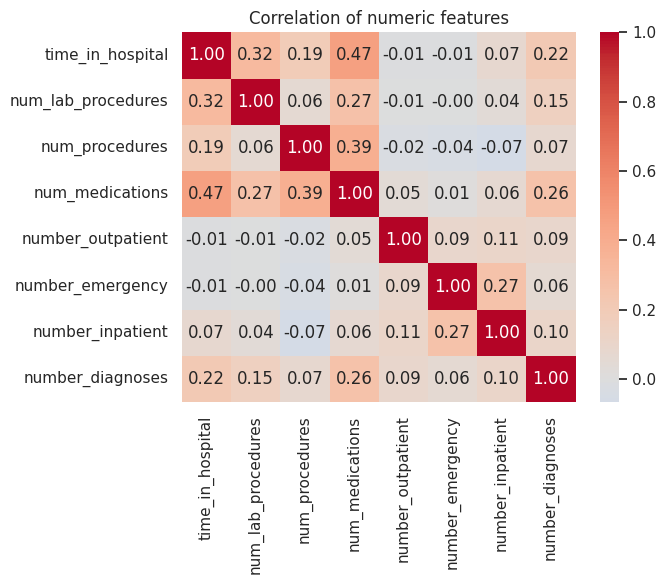

In [10]:
corr = raw[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of numeric features")
plt.tight_layout(); plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=200); plt.show()

**Interpretation (write your own):** Are any features strongly correlated (e.g., `time_in_hospital` and `num_medications`)? What does that imply for linear models (multicollinearity) versus tree-based models?

### 3.6 Near-constant columns

In [11]:
def near_constant_report(df: pd.DataFrame, threshold: float = 0.99) -> pd.DataFrame:
    rows = []
    for c in df.select_dtypes(include="object").columns:
        top_share = df[c].value_counts(normalize=True, dropna=False).iloc[0]
        if top_share >= threshold:
            rows.append({"column": c, "top_value": df[c].value_counts(dropna=False).index[0],
                         "top_share_pct": round(top_share * 100, 2)})
    return pd.DataFrame(rows).set_index("column") if rows else pd.DataFrame()

near_constant_report(raw)

,top_value,top_share_pct
column,,
nateglinide,No,99.31
chlorpropamide,No,99.92
acetohexamide,No,100.00
tolbutamide,No,99.98
acarbose,No,99.70
miglitol,No,99.96
troglitazone,No,100.00
tolazamide,No,99.96
examide,No,100.00


**Interpretation (write your own):** Which medication columns carry almost no information? Constant columns are dropped in Section 4; near-constant ones may be kept, grouped, or dropped, so state which you chose and why.

### 3.7 Repeat patients (leakage check)

In [12]:
enc_per_patient = raw.groupby("patient_nbr").size()
repeat_patients = (enc_per_patient > 1).sum()
rows_from_repeat = enc_per_patient[enc_per_patient > 1].sum()

print(f"Unique patients: {enc_per_patient.shape[0]:,}")
print(f"Patients with >1 encounter: {repeat_patients:,} ({repeat_patients / enc_per_patient.shape[0]:.1%} of patients)")
print(f"Encounters belonging to repeat patients: {rows_from_repeat:,} ({rows_from_repeat / len(raw):.1%} of rows)")
print(f"Max encounters for one patient: {enc_per_patient.max()}")

Unique patients: 71,518
Patients with >1 encounter: 16,773 (23.5% of patients)
Encounters belonging to repeat patients: 47,021 (46.2% of rows)
Max encounters for one patient: 40


**Interpretation (write your own):** A random row-level split would put encounters from the *same patient* in both train and test, so the model could memorize patient-specific patterns and the test score would be optimistic (data leakage). Section 4 therefore splits **by patient**. State this as a methodological choice in the report.

## 4. Data cleaning and patient-level split
Cleaning decisions, each tied to the EDA above:

1. **Remove encounters ending in death or hospice** (`discharge_disposition_id` in 11, 13, 14, 19, 20, 21): these patients cannot be readmitted, so keeping them would bias the target.
2. **Remove the few `Unknown/Invalid` gender rows**: too few to model.
3. **Drop `weight`** (almost entirely missing) and `encounter_id` (identifier with no predictive meaning).
4. **Label missing `race`, `payer_code`, `medical_specialty` and diagnosis codes as "Unknown"**, keeping missingness as potential signal rather than guessing values.
5. **Drop constant columns** (zero information).
6. **Treat admission/discharge/source IDs as categorical**, since they are codes, not quantities.

`patient_nbr` is kept for now because it is needed for the group split; it is **dropped before modeling** (Section 5).

In [13]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Apply all cleaning decisions documented above. Returns a new DataFrame."""
    out = df.copy()
    n0 = len(out)

    out = out[~out["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)]
    n1 = len(out)
    out = out[out["gender"] != "Unknown/Invalid"]
    n2 = len(out)

    out = out.drop(columns=[c for c in ["weight", "encounter_id"] if c in out.columns])

    for col in ["race", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3"]:
        out[col] = out[col].fillna("Unknown")

    constant_cols = [c for c in out.columns if out[c].nunique(dropna=False) == 1]
    out = out.drop(columns=constant_cols)

    for col in ID_CODE_COLS:
        out[col] = out[col].astype(str)

    print(f"Removed {n0 - n1:,} expired/hospice encounters and {n1 - n2:,} invalid-gender rows")
    print(f"Dropped constant columns: {constant_cols}")
    print(f"Clean shape: {out.shape[0]:,} rows x {out.shape[1]} columns")
    return out.reset_index(drop=True)

clean = clean_data(raw)
assert clean.drop(columns=["patient_nbr"]).isna().sum().sum() == 0, "Unexpected missing values remain"
clean.head()

Removed 2,423 expired/hospice encounters and 3 invalid-gender rows
Dropped constant columns: ['examide', 'citoglipton']
Clean shape: 99,340 rows x 46 columns


,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,Unknown,...,No,No,No,No,No,No,No,No,Yes,NO
3,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,Unknown,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [14]:
def split_by_patient(df: pd.DataFrame, val_size: float = 0.15, test_size: float = 0.15, seed: int = SEED):
    """Train/val/test split where no patient appears in more than one subset."""
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trainval_idx, test_idx = next(gss.split(df, groups=df["patient_nbr"]))
    trainval, test = df.iloc[trainval_idx], df.iloc[test_idx]

    gss2 = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    train_idx, val_idx = next(gss2.split(trainval, groups=trainval["patient_nbr"]))
    return trainval.iloc[train_idx].copy(), trainval.iloc[val_idx].copy(), test.copy()

train_df, val_df, test_df = split_by_patient(clean)

# Leakage check: no patient may appear in two subsets
p_tr, p_va, p_te = (set(d["patient_nbr"]) for d in (train_df, val_df, test_df))
assert not (p_tr & p_va or p_tr & p_te or p_va & p_te), "Patient leakage between splits!"

summary = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "patients": [len(p_tr), len(p_va), len(p_te)],
}, index=["train", "validation", "test"])
summary["row_share_%"] = (summary["rows"] / summary["rows"].sum() * 100).round(1)
display(summary)

class_mix = pd.concat({n: d[TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100
                       for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}, axis=1).round(2)
display(class_mix.rename_axis("class (% of split)"))

,rows,patients,row_share_%
train,69702,48990,70.2
validation,14823,10498,14.9
test,14815,10499,14.9


,train,validation,test
class (% of split),,,
NO,52.62,53.35,53.59
>30,35.92,35.33,35.31
<30,11.47,11.32,11.10


**Interpretation (write your own):** Confirm the class proportions are similar across splits, so validation and test scores are comparable to training. Record the final split sizes in the experiment table's "dataset splits" column.

In [15]:
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "val.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)
print("Saved cleaned splits to", PROCESSED_DIR.resolve())

Saved cleaned splits to /content/drive/MyDrive/diabetes_project/data/processed


## 5. Feature engineering *(Day 2)*
Planned: ICD-9 diagnosis grouping (`diag_1`-`diag_3` to broader disease categories), medication-change counts, prior-visit totals, age as an ordinal/midpoint feature, and an evaluated comparison against the raw-feature baseline.

## 6. Traditional machine learning *(Day 2)*

## 7. Deep learning with `tf.data` *(Day 3)*

## 8. Evaluation and error analysis *(Day 4)*

## 9. Experiment table and conclusions *(Day 4)*